# Lab: The Mean Value Theorem and Linear Approximation

Math 140H, Honors Calculus I

Two ideas from class, seen through computation: the Mean Value Theorem, and the fact that near a point, a differentiable function is almost its tangent line. At the end you will learn how to bound the error of the tangent-line approximation.

**How to use this notebook**

- ✏️ **On paper:** work this out by hand first (you will hand these pages in), then run the next cell to check.
- 🔬 **Explore:** change the numbers in the cell, or move the slider, and run the cell again.
- You never need to write code. Only change the inputs you are told to change, then press Shift+Enter.

Functions are typed like this: $x^3$ is `x**3`, $\sin x$ is `sp.sin(x)`, $\frac1x$ is `1/x`, $\lvert x\rvert$ is `abs(x)`, $\sqrt[3]{x}$ is `cbrt(x)`, $\pi$ is `sp.pi`.

**START BY RUNNING THE NEXT CELL.**

In [1]:
#| code-fold: true

#
#
# ALWAYS RUN THIS CELL FIRST!!
#
#

import numpy as np
import sympy as sp
import mpmath as mp
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from IPython.display import display, Math

plt.rcParams['figure.figsize'] = (7, 4.5)
WIDGET_DPI = 72          # on-screen size of the slider pictures: smaller number = smaller picture
x = sp.Symbol('x', real=True)
mp.mp.dps = 40

import io
try:
    import ipywidgets as widgets
    _WIDGETS = True
except ImportError:
    _WIDGETS = False


class cbrt(sp.Function):
    """Real cube root: cbrt(x) = x^(1/3), also for negative x."""
    @classmethod
    def eval(cls, arg):
        if arg.is_Number:
            return sp.sign(arg) * sp.Abs(arg) ** sp.Rational(1, 3)

    def fdiff(self, argindex=1):
        return 1 / (3 * cbrt(self.args[0]) ** 2)

    def _numpycode(self, printer):
        return f"{printer._module_format('numpy.cbrt')}({printer._print(self.args[0])})"

    def _mpmathcode(self, printer):
        a = printer._print(self.args[0])
        return (f"({printer._module_format('mpmath.sign')}({a})"
                f"*{printer._module_format('mpmath.cbrt')}(abs({a})))")

    def _latex(self, printer, exp=None):
        s = r"\sqrt[3]{%s}" % printer._print(self.args[0])
        return s if exp is None else r"\left(%s\right)^{%s}" % (s, exp)


# ---------------------------------------------------------------- helpers
def _exact(v):
    v = sp.sympify(v)
    return sp.nsimplify(v, rational=True) if isinstance(v, sp.Float) else v


def _fmt(v, digits=8):
    return f'{float(v):.{digits}g}'


def _np(f):
    F = sp.lambdify(x, f, 'numpy')
    def G(t):
        with np.errstate(all='ignore'):
            return np.asarray(F(t), dtype=float) * np.ones_like(t, dtype=float)
    return G


def _mp(f):
    return sp.lambdify(x, f, 'mpmath')


def _value(f, a):
    """f(a), using a limit if the formula is undefined at a (as for x*sin(1/x) at 0)."""
    v = f.subs(x, a)
    if v.has(sp.nan, sp.zoo, sp.oo, -sp.oo):
        v = sp.limit(f, x, a)
    return v


def _slope_at(f, a):
    """f'(a) if f is differentiable at a, otherwise None (checked with one-sided difference quotients)."""
    F, A, fa = _mp(f), mp.mpf(sp.N(a, 50)), mp.mpf(sp.N(_value(f, a), 50))
    qs = []
    for h in [mp.mpf('1e-15'), mp.mpf('1e-20')]:
        for s in (1, -1):
            try:
                qs.append((F(A + s * h) - fa) / (s * h))
            except Exception:
                return None
    if any((not mp.isfinite(q)) or abs(q) > 1e8 for q in qs) or max(qs) - min(qs) > 1e-6:
        return None
    d = sp.diff(f, x).subs(x, a)
    return sp.nsimplify(d) if d.is_finite else None


def _p(v):
    """LaTeX of a number, in parentheses if negative."""
    v = sp.nsimplify(v)
    return rf"\left({sp.latex(v)}\right)" if (v.is_real and v < 0) else sp.latex(v)


def _show(label, expr):
    display(Math(label + sp.latex(sp.nsimplify(expr)) +
                 (r"\approx " + _fmt(expr) if not sp.sympify(expr).is_Integer else "")))


def _slider_view(draw, sliders):
    """Show draw(**slider values) -> (figure, text) and update it in place when a slider moves.

    The figure is rendered to a PNG and swapped into an Image widget of fixed on-screen size,
    so the output area is never cleared and nothing on the page moves."""
    if not _WIDGETS:
        print('(No sliders available here: showing the starting values.)')
        fig, text = draw(**{k: sl.value if hasattr(sl, 'value') else sl for k, sl in sliders.items()})
        plt.show(); print(text)
        return
    img = widgets.Image(format='png')
    txt = widgets.HTML()
    def update(change=None):
        fig, text = draw(**{k: sl.value for k, sl in sliders.items()})
        w_in, h_in = fig.get_size_inches()
        # on-screen size in CSS pixels; rendered at twice that resolution so it stays sharp
        img.layout.width, img.layout.height = f'{round(w_in * WIDGET_DPI)}px', f'{round(h_in * WIDGET_DPI)}px'
        buf = io.BytesIO()
        fig.savefig(buf, format='png', dpi=2 * WIDGET_DPI)   # fixed size: no 'tight' cropping
        plt.close(fig)
        img.value = buf.getvalue()
        txt.value = ('<pre style="font-family: monospace; font-size: 12px; margin: 0">'
                     + text + '</pre>')
    for sl in sliders.values():
        sl.observe(update, names='value')
    update()
    # align_items='flex-start' stops the box from stretching the picture to the full cell width
    display(widgets.VBox(list(sliders.values()) + [img, txt],
                         layout=widgets.Layout(align_items='flex-start')))


def _slider(description, lo, hi, step, value):
    return widgets.FloatSlider(min=lo, max=hi, step=step, value=value, description=description,
                               readout_format='.2f', continuous_update=True,
                               layout=widgets.Layout(width='400px')) if _WIDGETS else value


# ---------------------------------------------------------------- Part 1
def _witnesses(f, a, b, m):
    dF = _np(sp.diff(f, x))
    xs = np.linspace(float(a), float(b), 20001)[1:-1]
    g = dF(xs) - float(m)
    out = []
    for i in range(len(xs) - 1):
        if g[i] == 0:
            out.append(xs[i])
        elif np.isfinite(g[i]) and np.isfinite(g[i + 1]) and g[i] * g[i + 1] < 0:
            c = brentq(lambda t: float(dF(np.array([t]))[0]) - float(m), xs[i], xs[i + 1])
            if abs(float(dF(np.array([c]))[0]) - float(m)) < 1e-7:   # skip jumps of f'
                out.append(c)
    return out


def _plot_mvt(f, a, b, xis, title):
    F, dF = _np(f), _np(sp.diff(f, x))
    A, B = float(a), float(b)
    pad = 0.15 * (B - A)
    xs = np.linspace(A - pad, B + pad, 1500)
    m = (F(np.array([B]))[0] - F(np.array([A]))[0]) / (B - A)
    plt.plot(xs, F(xs), lw=2, label='$y=f(x)$')
    plt.plot([A, B], [F(np.array([A]))[0], F(np.array([B]))[0]], 'ko-', label=f'secant, slope {m:.4g}')
    for k, c in enumerate(xis):
        t = np.linspace(c - 0.3 * (B - A), c + 0.3 * (B - A), 2)
        fc = F(np.array([c]))[0]
        plt.plot(t, fc + m * (t - c), 'r--', label='tangent at $\\xi$' if k == 0 else None)
        plt.plot(c, fc, 'ro')
    plt.axvline(A, color='0.6', lw=0.8); plt.axvline(B, color='0.6', lw=0.8)
    plt.title(title); plt.legend(); plt.show()


def mvt(f, a, b):
    """Secant slope of f on [a, b], every xi in (a, b) with f'(xi) = slope, and a picture."""
    f, a, b = sp.sympify(f), _exact(a), _exact(b)
    m = sp.nsimplify((f.subs(x, b) - f.subs(x, a)) / (b - a))
    display(Math(rf"f(x) = {sp.latex(f)}, \qquad f'(x) = {sp.latex(sp.diff(f, x))}, \qquad [a,b] = [{sp.latex(a)}, {sp.latex(b)}]"))
    _show(r"\text{secant slope } \frac{f(b)-f(a)}{b-a} = ", m)
    xis = _witnesses(f, a, b, m)
    if not xis:
        print("There is NO xi in (a, b) with f'(xi) = secant slope.")
    for c in xis:
        print(f"xi = {c:.8g}   (relative position (xi - a)/(b - a) = {(c - float(a)) / float(b - a):.6f})")
    _plot_mvt(f, a, b, xis, f'Mean Value Theorem on [{a}, {b}]')


def mvt_explorer(f, lo=-3, hi=3):
    """Sliders for a and b; shows the secant, the tangents at every xi, and where xi sits."""
    f = sp.sympify(f)
    F, dF = _np(f), _np(sp.diff(f, x))
    # fixed axes for every slider position: the graph over the whole slider range
    pad = 0.05 * (hi - lo)
    xs = np.linspace(lo - pad, hi + pad, 1500)
    ys = F(xs)
    ymin, ymax = np.nanmin(ys), np.nanmax(ys)
    ymargin = 0.08 * (ymax - ymin) + 1e-9

    def draw(a, b):
        fig = plt.figure(figsize=(7, 4.5))
        fig.subplots_adjust(left=0.1, right=0.97, bottom=0.1, top=0.92)
        ax = fig.add_subplot()
        ax.plot(xs, ys, lw=2, label='$y=f(x)$')
        ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(ymin - ymargin, ymax + ymargin)
        ax.set_title(f'$f(x) = {sp.latex(f)}$')
        lines = []
        if b <= a + 1e-9:
            ax.legend(loc='upper left')
            return fig, 'Choose b > a.\n\n\n'
        A, B = _exact(round(a, 4)), _exact(round(b, 4))
        m = float((f.subs(x, B) - f.subs(x, A)) / (B - A))
        xis = _witnesses(f, A, B, m)
        fa, fb = F(np.array([a]))[0], F(np.array([b]))[0]
        ax.plot([a, b], [fa, fb], 'ko-', label='secant')
        ax.axvline(a, color='0.6', lw=0.8); ax.axvline(b, color='0.6', lw=0.8)
        for k, c in enumerate(xis):
            t = np.linspace(c - 0.3 * (b - a), c + 0.3 * (b - a), 2)
            fc = F(np.array([c]))[0]
            ax.plot(t, fc + m * (t - c), 'r--', label='tangent at $\\xi$' if k == 0 else None)
            ax.plot(c, fc, 'ro')
        ax.legend(loc='upper left')
        lines.append(f"secant slope = {m:+10.5f}      midpoint (a+b)/2 = {(a + b) / 2:+8.4f}")
        if not xis:
            lines.append("no xi in (a, b)")
        for c in xis[:3]:
            lines.append(f"xi = {c:+8.4f}     relative position (xi - a)/(b - a) = {(c - a) / (b - a):.4f}")
        lines += [''] * (4 - len(lines))
        return fig, '\n'.join(lines)

    _slider_view(draw, {'a': _slider('a', lo, hi, (hi - lo) / 120, -1.0),
                        'b': _slider('b', lo, hi, (hi - lo) / 120, 2.0)})


# ---------------------------------------------------------------- Part 2
def zoom(f, a):
    """Zoom in on the graph of f at (a, f(a)) with a slider. The window stays square."""
    f, a = sp.sympify(f), _exact(a)
    fa = float(_value(f, a)); A = float(a)
    d = _slope_at(f, a)
    F = _np(f)

    def draw(zoom_level):
        w = 10.0 ** (-zoom_level)
        u = np.linspace(-w, w, 4001)               # offsets from a
        fig = plt.figure(figsize=(5.8, 5.6))
        fig.subplots_adjust(left=0.19, right=0.87, bottom=0.12, top=0.9)
        ax = fig.add_subplot()
        ax.plot(u, F(A + u) - fa, lw=1.5, label='$y=f(x)$')
        if d is not None:
            ax.plot(u, float(d) * u, 'r--', lw=1.2, label='tangent')
        ax.plot(0, 0, 'ko', ms=4)
        ax.set_xlim(-w, w); ax.set_ylim(-w, w); ax.set_aspect('equal')
        # tick labels are offsets from the point (a, f(a)), always in the same format
        ticks = [-w, 0, w]
        labels = [f'{-w:+.1e}', '0', f'{w:+.1e}']
        ax.set_xticks(ticks, labels); ax.set_yticks(ticks, labels)
        ax.set_xlabel('$x - a$'); ax.set_ylabel('$y - f(a)$')
        ax.set_title(f'$f(x)={sp.latex(f)}$ near $a={sp.latex(a)}$')
        ax.legend(loc='upper left')
        if d is None:
            text = (f"window: x within {w:.1e} of a\n"
                    "f is not differentiable at a: there is no tangent line to draw.")
        else:
            gap = np.nanmax(np.abs(F(A + u) - fa - float(d) * u))
            text = (f"window: x within {w:.1e} of a\n"
                    f"largest vertical gap between graph and tangent: {gap:.3e}"
                    f"  =  {gap / w:.3e} x (half-width of the window)")
        return fig, text

    _slider_view(draw, {'zoom_level': _slider('zoom', 0, 6, 0.25, 0.0)})


def eps_table(f, a, hs=(0.1, 0.01, 0.001, 0.0001, -0.1, -0.01, -0.001, -0.0001), slope=None):
    """Errors of the approximation f(a+h) ~ f(a) + slope*h (slope = f'(a) unless given)."""
    f, a = sp.sympify(f), _exact(a)
    fa = _value(f, a)
    d = sp.diff(f, x).subs(x, a) if slope is None else _exact(slope)
    which = "L(a+h) = f(a) + f'(a)\\,h" if slope is None else "\\ell(a+h) = f(a) + (\\text{slope})\\,h"
    display(Math(rf"f(x) = {sp.latex(f)},\quad a = {sp.latex(a)},\quad f(a) = {sp.latex(sp.nsimplify(fa))},\quad "
                 + (rf"f'(a) = {sp.latex(sp.nsimplify(d))}" if slope is None else rf"\text{{slope}} = {sp.latex(d)}")
                 + rf",\qquad {which}"))
    print(f"{'h':>9} {'f(a+h)':>14} {'line at a+h':>14} {'error eps*h':>13} {'eps':>12} {'error / h^2':>12}")
    for h in hs:
        H = _exact(h)
        val = sp.N(f.subs(x, a + H), 40)
        lin = sp.N(fa + d * H, 40)
        err = val - lin
        print(f"{float(H):9g} {float(val):14.10f} {float(lin):14.10f} {float(err):13.4e} "
              f"{float(err / H):12.4e} {float(err / H**2):12.6f}")


# ---------------------------------------------------------------- Part 3
def error_bound(f, a, h, tol=None):
    """Linear approximation of f(a+h), its actual error, and the bound M h^2."""
    f, a, h = sp.sympify(f), _exact(a), _exact(h)
    fa, d1, f2 = _value(f, a), sp.diff(f, x).subs(x, a), sp.diff(f, x, 2)
    L = fa + d1 * h
    true = sp.N(f.subs(x, a + h), 30)
    err = true - sp.N(L, 30)
    lo, hi = sorted([float(a), float(a + h)])
    ts = np.linspace(lo, hi, 20001)
    M = float(np.nanmax(np.abs(_np(f2)(ts))))
    bound = M * float(h) ** 2
    display(Math(rf"f(x) = {sp.latex(f)},\quad a = {sp.latex(a)},\quad h = {sp.latex(h)},\qquad "
                 rf"L(a+h) = f(a) + f'(a)\,h = {_p(fa)} + {_p(d1)}\cdot{_p(h)}"))
    print(f"linear approximation L(a+h) = {float(L):.10f}")
    print(f"true value         f(a+h) = {float(true):.10f}")
    print(f"actual error  f(a+h) - L(a+h) = {float(err):.4e}")
    display(Math(rf"f''(x) = {sp.latex(f2)}"))
    print(f"M = largest |f''(x)| for x between {lo:.6g} and {hi:.6g}:  {M:.6g}")
    print(f"error bound M h^2 = {bound:.4e}      (actual error)/(bound) = {abs(float(err)) / bound:.3f}")
    if tol is not None:
        print(f"\nbound < {tol}?  {'yes' if bound < tol else 'NO'}      actual error < {tol}?  {'yes' if abs(float(err)) < tol else 'NO'}")


# ---------------------------------------------------------------- Part 4
def xi_table(f, a, hs=(1, 0.1, 0.01, 0.001, 0.0001, -0.1, -0.001)):
    """For the MVT on the interval between a and a+h: where is xi, relative to the interval?"""
    f, a = sp.sympify(f), _exact(a)
    F, dF = _mp(f), _mp(sp.diff(f, x))
    A = mp.mpf(sp.N(a, 50))
    display(Math(rf"f(x) = {sp.latex(f)},\quad a = {sp.latex(a)}"))
    print(f"{'h':>9} {'xi':>16} {'(xi - a)/h':>14}")
    for h in hs:
        H = mp.mpf(sp.N(_exact(h), 50))
        m = (F(A + H) - F(A)) / H
        lo, hi = (A, A + H) if H > 0 else (A + H, A)
        try:
            xi = mp.findroot(lambda t: dF(t) - m, (lo, hi), solver='anderson')
            print(f"{float(H):9g} {float(xi):16.10f} {float((xi - A) / H):14.8f}")
        except Exception:
            print(f"{float(H):9g}   (no unique xi found)")


def done():
    print('Setup complete.')
done()

Setup complete.


## Finding $\xi$

**Mean Value Theorem.** If $f$ is continuous on $[a,b]$ and differentiable on $(a,b)$, there is a $\xi\in(a,b)$ with
$$f'(\xi) = \frac{f(b)-f(a)}{b-a}.$$
The theorem says $\xi$ exists, but not where it is. Here we find it.

✏️ **1.1 On paper.** Let $f(x) = x^3$.
- On $[0,3]$: compute the secant slope and find **all** $\xi$ in $(0,3)$.
- On $[-1,2]$: same question. Careful: which solutions lie in the *open* interval?

Then run the next two cells.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

xi = 1.7320508   (relative position (xi - a)/(b - a) = 0.577350)


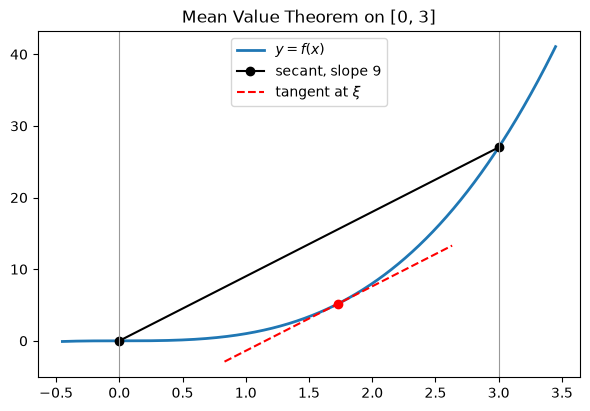

In [2]:
mvt(x**3, 0, 3)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

xi = 1   (relative position (xi - a)/(b - a) = 0.666667)


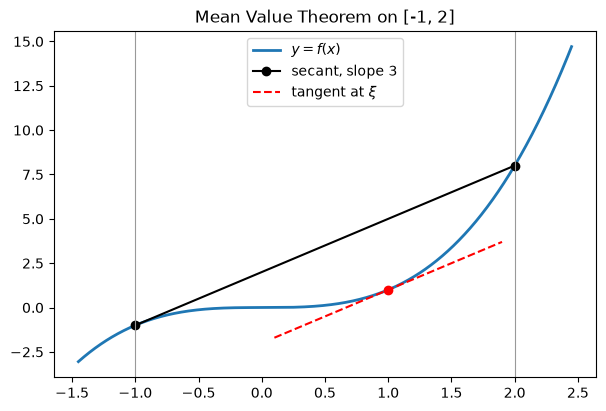

In [3]:
mvt(x**3, -1, 2)

✏️ **1.2 On paper.** Let $f(x) = \lvert x-1\rvert-x$ on $[-1,2]$. Compute the secant slope. Is there a $\xi$? Which hypothesis of the MVT fails?

<IPython.core.display.Math object>

<IPython.core.display.Math object>

There is NO xi in (a, b) with f'(xi) = secant slope.


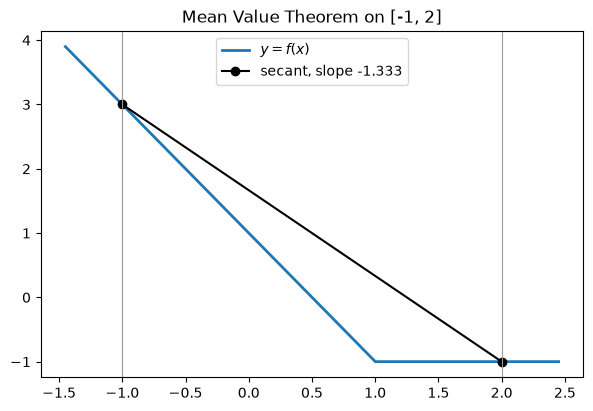

In [4]:
mvt(abs(x-1)-x, -1, 2)

🔬 **1.3 Explore.** $f(x)=\sqrt[3]{x}$ is **not** differentiable at $0$ (vertical tangent). Run the cell below. Does a $\xi$ exist anyway?

✏️ On paper, explain in one sentence why this does not contradict the MVT.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

xi = -0.19245009   (relative position (xi - a)/(b - a) = 0.403775)
xi = 0.19245009   (relative position (xi - a)/(b - a) = 0.596225)


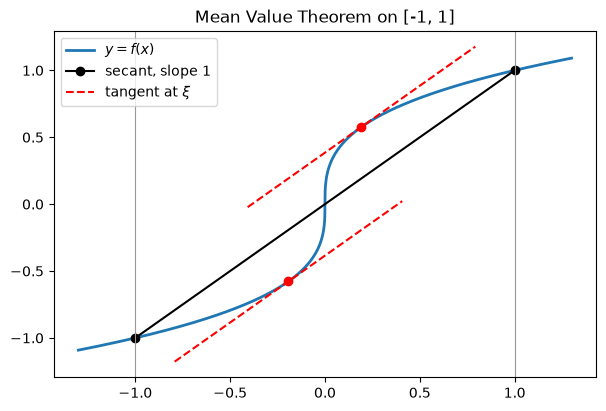

In [5]:
mvt(cbrt(x), -1, 1)

🔬 **1.4 Explore.** Move the sliders for $a$ and $b$. The output shows the **relative position** $\dfrac{\xi-a}{b-a}$ of $\xi$ in the interval ($0$ = left end, $1$ = right end).

- For $f(x)=x^2$: where is $\xi$, for every choice of $a$ and $b$? Now replace `x**2` by another quadratic, such as `3*x**2 - 5*x + 1`. Same?
- For `x**3` with $a = 0$: record the relative position for three different $b>0$. What do you notice?

✏️ **1.5 On paper.** Explain both observations by computation:
- For $f(x) = px^2+qx+r$, compute the secant slope on $[a,b]$ and solve $f'(\xi) = $ slope.
- For $f(x) = x^3$ on $[0,b]$, find $\xi$ and the relative position.

In [6]:
mvt_explorer(x**2)

## The tangent line as an approximation

Let us write the approximation through the tangent line as follows:

$$f(a+h) = f(a) + f'(a)\,h + \varepsilon \, h.$$

Here $\varepsilon$ is an **error term that depends on $h$**.

Then $f$ is differentiable at $a$ exactly when $\varepsilon\to0$ as $h\to0$. Geometrically, this says: **zoom in on the graph, and it looks more and more like the tangent line.**

✏️ **2.1 On paper (predict).** For each function, decide: if you zoom in on the graph at $x=a$, will it look like a straight line? If so, which line?

| | $f(x)$ | $a$ |
|---|---|---|
| (a) | $x^2$ | $1$ |
| (b) | $\lvert x\rvert$ | $0$ |
| (c) | $\sqrt[3]{x}$ | $0$ |
| (d) | $x\sin(1/x)$ (with $f(0)=0$) | $0$ |

🔬 Then check each one by changing the function and $a$ in the cell below. Move the zoom slider all the way.

In [7]:
zoom(x**2, 1)

# other inputs to try:   abs(x), 0        cbrt(x), 0        x*sp.sin(1/x), 0

✏️ **2.2 On paper.** Let $f(x)=\frac1x$ and $a=1$.
- Find $L(x) = f(1) + f'(1)(x-1)$.
- For $h = 0.1$: compute $f(1.1)$, $L(1.1)$, the error $\varepsilon h = f(1.1) - L(1.1)$, and $\varepsilon$, as exact fractions.
- For general $h$: show that $\varepsilon h = \dfrac{h^2}{1+h}$.

Check with the table (the column `error eps*h` is $f(a+h) - L(a+h)$).

In [8]:
eps_table(1/x, 1)

<IPython.core.display.Math object>

        h         f(a+h)    line at a+h   error eps*h          eps  error / h^2
      0.1   0.9090909091   0.9000000000    9.0909e-03   9.0909e-02     0.909091
     0.01   0.9900990099   0.9900000000    9.9010e-05   9.9010e-03     0.990099
    0.001   0.9990009990   0.9990000000    9.9900e-07   9.9900e-04     0.999001
   0.0001   0.9999000100   0.9999000000    9.9990e-09   9.9990e-05     0.999900
     -0.1   1.1111111111   1.1000000000    1.1111e-02  -1.1111e-01     1.111111
    -0.01   1.0101010101   1.0100000000    1.0101e-04  -1.0101e-02     1.010101
   -0.001   1.0010010010   1.0010000000    1.0010e-06  -1.0010e-03     1.001001
  -0.0001   1.0001000100   1.0001000000    1.0001e-08  -1.0001e-04     1.000100


The error $\varepsilon h$ goes to $0$ much faster than $h$. The last column compares it with $h^2$.

🔬 **2.3 Explore.** Run the table for each row below, and on paper fill in the missing columns: the value that `error / h^2` approaches, and $f''(a)$ (the derivative of $f'$, computed by hand).

| $f(x)$ | $a$ | `error / h^2` $\to$ ? | $f''(a)$ |
|---|---|---|---|
| `1/x` | `1` | | |
| `x**3` | `1` | | |
| `sp.sin(x)` | `sp.pi/6` | | |
| `sp.cos(x)` | `0` | | |
| `x**3 - 2*x + 4` | `1` | | |

✏️ Write down a conjecture: $\displaystyle\lim_{h\to0}\frac{\varepsilon h}{h^2} = \ ?$

In [9]:
eps_table(x**3 - 2*x + 4, 1)

<IPython.core.display.Math object>

        h         f(a+h)    line at a+h   error eps*h          eps  error / h^2
      0.1   3.1310000000   3.1000000000    3.1000e-02   3.1000e-01     3.100000
     0.01   3.0103010000   3.0100000000    3.0100e-04   3.0100e-02     3.010000
    0.001   3.0010030010   3.0010000000    3.0010e-06   3.0010e-03     3.001000
   0.0001   3.0001000300   3.0001000000    3.0001e-08   3.0001e-04     3.000100
     -0.1   2.9290000000   2.9000000000    2.9000e-02  -2.9000e-01     2.900000
    -0.01   2.9902990000   2.9900000000    2.9900e-04  -2.9900e-02     2.990000
   -0.001   2.9990029990   2.9990000000    2.9990e-06  -2.9990e-03     2.999000
  -0.0001   2.9999000300   2.9999000000    2.9999e-08  -2.9999e-04     2.999900


🔬 **2.4 Explore. Is the tangent special?** Use a line through $(a, f(a))$ with a slope slightly *different* from $f'(a)$. Below, $f(x) = x^2$, $a=1$ and $f'(1) = 2$, but the line uses slope $2.01$. What happens to the `eps` column as $h\to0$? Try other slopes.

✏️ On paper: which slope is the only one for which the error is small compared to $h$?

In [10]:
eps_table(x**2, 1, slope=2.001)

<IPython.core.display.Math object>

        h         f(a+h)    line at a+h   error eps*h          eps  error / h^2
      0.1   1.2100000000   1.2001000000    9.9000e-03   9.9000e-02     0.990000
     0.01   1.0201000000   1.0200100000    9.0000e-05   9.0000e-03     0.900000
    0.001   1.0020010000   1.0020010000    0.0000e+00   0.0000e+00     0.000000
   0.0001   1.0002000100   1.0002001000   -9.0000e-08  -9.0000e-04    -9.000000
     -0.1   0.8100000000   0.7999000000    1.0100e-02  -1.0100e-01     1.010000
    -0.01   0.9801000000   0.9799900000    1.1000e-04  -1.1000e-02     1.100000
   -0.001   0.9980010000   0.9979990000    2.0000e-06  -2.0000e-03     2.000000
  -0.0001   0.9998000100   0.9997999000    1.1000e-07  -1.1000e-03    11.000000


## Bounding the error with the second derivative

We want a **guarantee** for the size of the error $\varepsilon h$, without knowing $f(a+h)$. Take $h>0$.

**Step 1.** By the MVT on $[a, a+h]$, $\dfrac{f(a+h)-f(a)}{h} = f'(\xi)$ for some $\xi\in(a,a+h)$. Comparing with $\dfrac{f(a+h)-f(a)}{h} = f'(a) + \varepsilon$ gives
$$\varepsilon = f'(\xi) - f'(a).$$

**Step 2.** Apply the MVT **again**, now to the function $f'$ on $[a,\xi]$. Its derivative is the **second derivative** $f'' = (f')'$. So there is $\eta\in(a,\xi)$ with
$$f'(\xi) - f'(a) = f''(\eta)\,(\xi - a).$$

**Step 3.** Since $0 < \xi - a < h$, if $\lvert f''\rvert \le M$ on $[a,a+h]$, then $\lvert\varepsilon\rvert \le M h$. Multiply by $h$:

> **Theorem (error of the linear approximation).** Let $f$ be twice differentiable on an open interval containing $a$ and $a+h$, and $\lvert f''(x)\rvert\le M$ for all $x$ between $a$ and $a+h$. Then
> $$\lvert f(a+h) - L(a+h)\rvert \le M h^2 .$$

(For $h<0$, use the interval $[a+h,a]$ instead; the result is the same.)

✏️ **3.1 On paper.** For each approximation: find $L(a+h)$, a bound $M$ for $\lvert f''\rvert$ between $a$ and $a+h$, and the error bound $Mh^2$.
- (a) $\dfrac{1}{0.9}$, using $f(x)=\frac1x$, $a=1$, $h=-0.1$. (Is $\lvert f''\rvert$ largest at $0.9$ or at $1$?)
- (b) $\sin 31^\circ$, using $f(x)=\sin x$, $a=\frac\pi6$ ($=30^\circ$) and $h = \frac{\pi}{180}$ ($=1^\circ$). (A simple choice is $M=1$.) How many decimal places of $\sin 31^\circ$ does your bound guarantee?

The cells compute $M$ as the exact largest value of $\lvert f''\rvert$; yours may be larger, which is fine.

In [11]:
error_bound(1/x, 1, -0.1)

<IPython.core.display.Math object>

linear approximation L(a+h) = 1.1000000000
true value         f(a+h) = 1.1111111111
actual error  f(a+h) - L(a+h) = 1.1111e-02


<IPython.core.display.Math object>

M = largest |f''(x)| for x between 0.9 and 1:  2.74348
error bound M h^2 = 2.7435e-02      (actual error)/(bound) = 0.405


In [12]:
error_bound(sp.sin(x), sp.pi/6, sp.pi/180)

<IPython.core.display.Math object>

linear approximation L(a+h) = 0.5151149947
true value         f(a+h) = 0.5150380749
actual error  f(a+h) - L(a+h) = -7.6920e-05


<IPython.core.display.Math object>

M = largest |f''(x)| for x between 0.523599 and 0.541052:  0.515038
error bound M h^2 = 1.5689e-04      (actual error)/(bound) = 0.490


✏️ **3.2 On paper (error budget).** You want to approximate $\frac{1}{1+h}$ by $L(1+h) = 1-h$, for $h>0$, with error **guaranteed** below $0.001$. Use the theorem to find how large $h$ may be.

🔬 Enter your $h$ in the cell and run it. Then increase $h$ to find (to 3 decimals) the largest $h$ for which the **actual** error is still below $0.001$.

✏️ Your guaranteed $h$ and the actual largest $h$ differ by a factor of about $\sqrt2$. Use your conjecture from 2.3 to explain why. (Remember $f''(1) = 2$.)

In [13]:
h = 0.05          # <- change this

error_bound(1/x, 1, h, tol=0.001)

<IPython.core.display.Math object>

linear approximation L(a+h) = 0.9500000000
true value         f(a+h) = 0.9523809524
actual error  f(a+h) - L(a+h) = 2.3810e-03


<IPython.core.display.Math object>

M = largest |f''(x)| for x between 1 and 1.05:  2
error bound M h^2 = 5.0000e-03      (actual error)/(bound) = 0.476

bound < 0.001?  NO      actual error < 0.001?  NO
